In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib streamlit


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import joblib

In [4]:
df = pd.read_csv("swiggy.csv")

In [5]:
df

,id,name,city,rating,rating_count,cost,cuisine,lic_no,link,address,menu
0,567335,AB FOODS POINT,Abohar,--,Too Few Ratings,₹ 200,"Beverages,Pizzas",22122652000138,https://www.swiggy.com/restaurants/ab-foods-po...,"AB FOODS POINT, NEAR RISHI NARANG DENTAL CLINI...",Menu/567335.json
1,531342,Janta Sweet House,Abohar,4.4,50+ ratings,₹ 200,"Sweets,Bakery",12117201000112,https://www.swiggy.com/restaurants/janta-sweet...,"Janta Sweet House, Bazar No.9, Circullar Road,...",Menu/531342.json
2,158203,theka coffee desi,Abohar,3.8,100+ ratings,₹ 100,Beverages,22121652000190,https://www.swiggy.com/restaurants/theka-coffe...,"theka coffee desi, sahtiya sadan road city",Menu/158203.json
3,187912,Singh Hut,Abohar,3.7,20+ ratings,₹ 250,"Fast Food,Indian",22119652000167,https://www.swiggy.com/restaurants/singh-hut-n...,"Singh Hut, CIRCULAR ROAD NEAR NEHRU PARK ABOHAR",Menu/187912.json
4,543530,GRILL MASTERS,Abohar,--,Too Few Ratings,₹ 250,"Italian-American,Fast Food",12122201000053,https://www.swiggy.com/restaurants/grill-maste...,"GRILL MASTERS, ADA Heights, Abohar - Hanumanga...",Menu/543530.json
...,...,...,...,...,...,...,...,...,...,...,...
148536,553122,The Food Delight,Yavatmal,--,Too Few Ratings,₹ 200,"Fast Food,Snacks",21522053000452,https://www.swiggy.com/restaurants/the-food-de...,"The Food Delight, 94MC+X35, New Singhania Naga...",Menu/553122.json
148537,562647,MAITRI FOODS & BEVERAGES,Yavatmal,--,Too Few Ratings,₹ 300,Pizzas,license,https://www.swiggy.com/restaurants/maitri-food...,"MAITRI FOODS & BEVERAGES, POLIC MITRYA SOCIETY...",Menu/562647.json
148538,559435,Cafe Bella Ciao,Yavatmal,--,Too Few Ratings,₹ 300,"Fast Food,Snacks",21522251000378,https://www.swiggy.com/restaurants/cafe-bella-...,"Cafe Bella Ciao, SHOP NO 2 NEMANI MARKET SBI S...",Menu/559435.json
148539,418989,GRILL ZILLA,Yavatmal,--,Too Few Ratings,₹ 250,Continental,21521251000241,https://www.swiggy.com/restaurants/grill-zilla...,"GRILL ZILLA, SHO NO 2/6, POSTEL GROUND CHOWPAT...",Menu/418989.json


In [6]:
df.head()

,id,name,city,rating,rating_count,cost,cuisine,lic_no,link,address,menu
0,567335,AB FOODS POINT,Abohar,--,Too Few Ratings,₹ 200,"Beverages,Pizzas",22122652000138,https://www.swiggy.com/restaurants/ab-foods-po...,"AB FOODS POINT, NEAR RISHI NARANG DENTAL CLINI...",Menu/567335.json
1,531342,Janta Sweet House,Abohar,4.4,50+ ratings,₹ 200,"Sweets,Bakery",12117201000112,https://www.swiggy.com/restaurants/janta-sweet...,"Janta Sweet House, Bazar No.9, Circullar Road,...",Menu/531342.json
2,158203,theka coffee desi,Abohar,3.8,100+ ratings,₹ 100,Beverages,22121652000190,https://www.swiggy.com/restaurants/theka-coffe...,"theka coffee desi, sahtiya sadan road city",Menu/158203.json
3,187912,Singh Hut,Abohar,3.7,20+ ratings,₹ 250,"Fast Food,Indian",22119652000167,https://www.swiggy.com/restaurants/singh-hut-n...,"Singh Hut, CIRCULAR ROAD NEAR NEHRU PARK ABOHAR",Menu/187912.json
4,543530,GRILL MASTERS,Abohar,--,Too Few Ratings,₹ 250,"Italian-American,Fast Food",12122201000053,https://www.swiggy.com/restaurants/grill-maste...,"GRILL MASTERS, ADA Heights, Abohar - Hanumanga...",Menu/543530.json


In [7]:
print("Shape:", df.shape)

Shape: (148541, 11)


In [8]:
df.columns

Index(['id', 'name', 'city', 'rating', 'rating_count', 'cost', 'cuisine',
       'lic_no', 'link', 'address', 'menu'],
      dtype='str')

In [9]:
df.isnull().sum()

id                0
name             86
city              0
rating           86
rating_count     86
cost            131
cuisine          99
lic_no          229
link              0
address          86
menu              0
dtype: int64

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148541 entries, 0 to 148540
Data columns (total 11 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   id            148541 non-null  int64
 1   name          148455 non-null  str  
 2   city          148541 non-null  str  
 3   rating        148455 non-null  str  
 4   rating_count  148455 non-null  str  
 5   cost          148410 non-null  str  
 6   cuisine       148442 non-null  str  
 7   lic_no        148312 non-null  str  
 8   link          148541 non-null  str  
 9   address       148455 non-null  str  
 10  menu          148541 non-null  str  
dtypes: int64(1), str(10)
memory usage: 53.1 MB


In [11]:
print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after:", df.duplicated().sum())

Duplicates before: 0
Duplicates after: 0


In [12]:
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

In [13]:
df["rating"].isnull().sum()

np.int64(87100)

In [14]:
df = df.dropna(subset=["rating"])

In [15]:
df["cost"] = (
    df["cost"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df["cost"] = pd.to_numeric(df["cost"], errors="coerce")

In [16]:
df[["cost", "rating"]].head()

,cost,rating
1,200.0,4.4
2,100.0,3.8
3,250.0,3.7
5,200.0,3.6
6,150.0,4.0


In [17]:
df = df.dropna(
    subset=["city", "cuisine", "rating", "cost"]
)

In [18]:
print(df.shape)

(61421, 11)


In [19]:
clean_df = df[
    [
        "id",
        "name",
        "city",
        "rating",
        "rating_count",
        "cost",
        "cuisine",
        "address",
        "link"
    ]
].copy()

In [20]:
clean_df.head()

,id,name,city,rating,rating_count,cost,cuisine,address,link
1,531342,Janta Sweet House,Abohar,4.4,50+ ratings,200.0,"Sweets,Bakery","Janta Sweet House, Bazar No.9, Circullar Road,...",https://www.swiggy.com/restaurants/janta-sweet...
2,158203,theka coffee desi,Abohar,3.8,100+ ratings,100.0,Beverages,"theka coffee desi, sahtiya sadan road city",https://www.swiggy.com/restaurants/theka-coffe...
3,187912,Singh Hut,Abohar,3.7,20+ ratings,250.0,"Fast Food,Indian","Singh Hut, CIRCULAR ROAD NEAR NEHRU PARK ABOHAR",https://www.swiggy.com/restaurants/singh-hut-n...
5,158204,Sam Uncle,Abohar,3.6,20+ ratings,200.0,Continental,"Sam Uncle, hanumangarh road near raja bajaj sh...",https://www.swiggy.com/restaurants/sam-uncle-c...
6,156588,shere punjab veg,Abohar,4.0,100+ ratings,150.0,North Indian,"shere punjab veg, major surinder chowk near ve...",https://www.swiggy.com/restaurants/shere-punja...


In [21]:
clean_df.to_csv(
    "swiggy_cleaned.csv",
    index=False
)

In [22]:
clean_df["city"].value_counts().head(10)

city
Bikaner                      850
Indiranagar,Bangalore        601
Noida-1                      545
Koramangala,Bangalore        483
HSR,Bangalore                445
BTM,Bangalore                434
Greater Kailash 2,Delhi      414
Whitefield,Bangalore         400
Electronic City,Bangalore    395
Bandra West,Mumbai           392
Name: count, dtype: int64

In [23]:
clean_df["cuisine"].value_counts().head(10)

cuisine
North Indian,Chinese    2910
Indian                  1931
North Indian            1870
Indian,Chinese          1826
South Indian            1644
Chinese                 1273
Pizzas                  1185
Bakery,Desserts         1098
Ice Cream,Desserts      1046
Chinese,North Indian     960
Name: count, dtype: int64

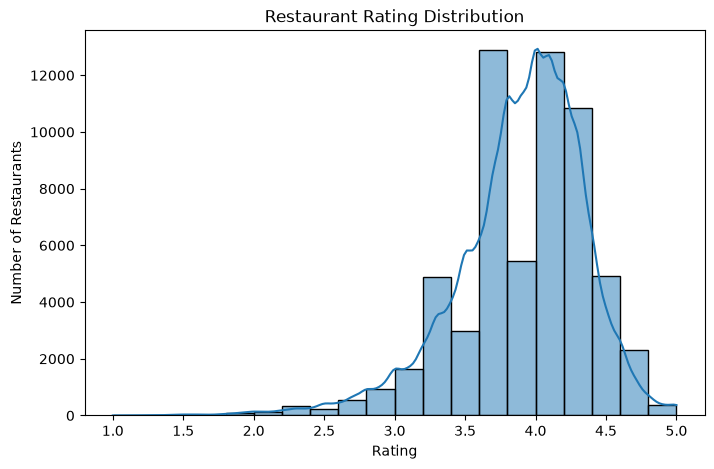

In [24]:
plt.figure(figsize=(8,5))

sns.histplot(
    clean_df["rating"],
    bins=20,
    kde=True
)

plt.title("Restaurant Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Restaurants")

plt.show()

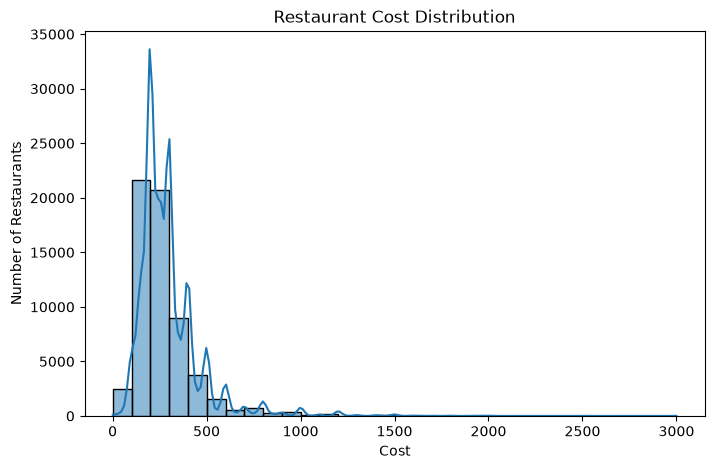

In [25]:
plt.figure(figsize=(8,5))

sns.histplot(
    clean_df["cost"],
    bins=30,
    kde=True
)

plt.title("Restaurant Cost Distribution")
plt.xlabel("Cost")
plt.ylabel("Number of Restaurants")

plt.show()

In [26]:
model_df = clean_df[
    [
        "city",
        "cuisine",
        "rating",
        "cost"
    ]
].copy()

In [27]:
city_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

city_encoded = city_encoder.fit_transform(
    model_df[["city"]]
)

In [28]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()

cuisine_encoded = mlb.fit_transform(
    model_df["cuisine"].fillna("").apply(
        lambda x: x.split(",")
    )
)

In [29]:
scaler = StandardScaler()

numeric_features = scaler.fit_transform(
    model_df[
        [
            "rating",
            "cost"
        ]
    ]
)

In [30]:
X = np.hstack(
    [
        city_encoded,
        cuisine_encoded,
        numeric_features
    ]
)

In [31]:
print(X.shape)

(61421, 896)


In [ ]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)

    inertia.append(kmeans.inertia_)

In [40]:
# Faster Elbow Method

sample_X = X[:10000]

inertia = []

for k in range(2, 11):
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=5
    )
    
    km.fit(sample_X)
    inertia.append(km.inertia_)
    
    print(f"K = {k}, Inertia = {km.inertia_}")

K = 2, Inertia = 38327.828195193404
K = 3, Inertia = 33283.11834014958
K = 4, Inertia = 31619.287574467464
K = 5, Inertia = 30115.28415463429
K = 6, Inertia = 29110.638502463484
K = 7, Inertia = 28449.690852473326
K = 8, Inertia = 27944.782598130543
K = 9, Inertia = 27316.56237722686
K = 10, Inertia = 26900.02910446563


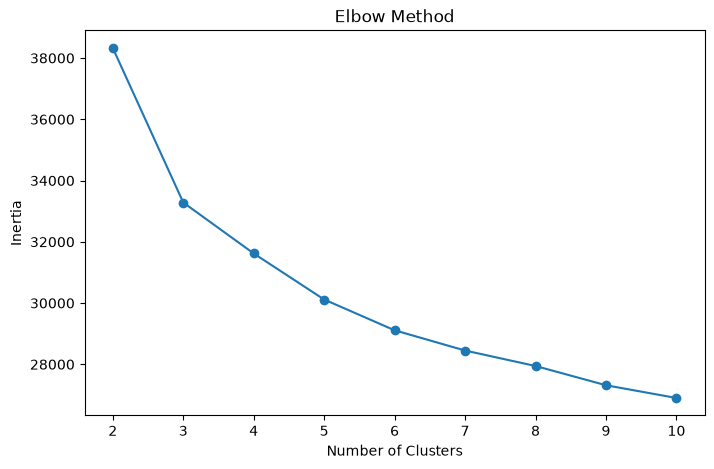

In [41]:
plt.figure(figsize=(8,5))

plt.plot(range(2, 11), inertia, marker="o")

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

In [42]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X)

print("K-Means clustering completed!")
print("Number of clusters:", len(set(clusters)))

K-Means clustering completed!
Number of clusters: 5


In [43]:
clean_df["cluster"] = clusters

print(clean_df.head())

       id               name    city  rating  rating_count   cost  \
1  531342  Janta Sweet House  Abohar     4.4   50+ ratings  200.0   
2  158203  theka coffee desi  Abohar     3.8  100+ ratings  100.0   
3  187912          Singh Hut  Abohar     3.7   20+ ratings  250.0   
5  158204          Sam Uncle  Abohar     3.6   20+ ratings  200.0   
6  156588   shere punjab veg  Abohar     4.0  100+ ratings  150.0   

            cuisine                                            address  \
1     Sweets,Bakery  Janta Sweet House, Bazar No.9, Circullar Road,...   
2         Beverages         theka coffee desi, sahtiya sadan road city   
3  Fast Food,Indian    Singh Hut, CIRCULAR ROAD NEAR NEHRU PARK ABOHAR   
5       Continental  Sam Uncle, hanumangarh road near raja bajaj sh...   
6      North Indian  shere punjab veg, major surinder chowk near ve...   

                                                link  cluster  
1  https://www.swiggy.com/restaurants/janta-sweet...        4  
2  https://w

In [44]:
print(clean_df["cluster"].value_counts().sort_index())

cluster
0     6888
1    22297
2    11450
3     1742
4    19044
Name: count, dtype: int64


In [45]:
from sklearn.metrics import silhouette_score

sil_score = silhouette_score(X, clusters)

print("Silhouette Score:", sil_score)

KeyboardInterrupt: 

In [46]:
from sklearn.metrics import silhouette_score

# Calculate silhouette score using 5,000 restaurants
sample_size = 5000

sil_score = silhouette_score(
    X[:sample_size],
    clusters[:sample_size]
)

print("Silhouette Score:", sil_score)

Silhouette Score: 0.09196918837924756


In [47]:
import joblib

joblib.dump(kmeans, "kmeans_model.pkl")

print("K-Means model saved successfully!")

K-Means model saved successfully!


In [48]:
joblib.dump(city_encoder, "city_encoder.pkl")

print("City encoder saved successfully!")

City encoder saved successfully!


In [49]:
joblib.dump(mlb, "cuisine_encoder.pkl")

print("Cuisine encoder saved successfully!")

Cuisine encoder saved successfully!


In [50]:
joblib.dump(scaler, "scaler.pkl")

print("Scaler saved successfully!")

Scaler saved successfully!


In [51]:
clean_df.to_csv("swiggy_final.csv", index=False)

print("Final Swiggy dataset saved successfully!")

Final Swiggy dataset saved successfully!


In [53]:
%%writefile app.py

UsageError: %%writefile is a cell magic, but the cell body is empty.


In [5]:
%%writefile swiggy_app.py

import streamlit as st
import pandas as pd
import joblib


# =========================================================
# PAGE CONFIGURATION
# =========================================================

st.set_page_config(
    page_title="Swiggy Restaurant Recommendation System",
    page_icon="🍽️",
    layout="wide",
    initial_sidebar_state="expanded"
)


# =========================================================
# DARK PURPLE THEME
# =========================================================

st.markdown(
    """
    <style>

    /* Main background */
    .stApp {
        background-color: #f8f5fb;
    }

    /* =====================================================
       SIDEBAR
       ===================================================== */

    section[data-testid="stSidebar"] {
        background-color: #24152f;
    }

    section[data-testid="stSidebar"] h1,
    section[data-testid="stSidebar"] h2,
    section[data-testid="stSidebar"] h3,
    section[data-testid="stSidebar"] label,
    section[data-testid="stSidebar"] p {
        color: white !important;
    }

    /* Navigation */
    section[data-testid="stSidebar"]
    div[role="radiogroup"] label {
        color: white !important;
    }

    /* Select boxes */
    section[data-testid="stSidebar"]
    div[data-baseweb="select"] {
        background-color: white !important;
        border-radius: 8px !important;
    }

    section[data-testid="stSidebar"]
    div[data-baseweb="select"] * {
        color: #222222 !important;
    }

    /* =====================================================
       MAIN TITLE
       ===================================================== */

    .main-title {
        font-size: 44px;
        font-weight: 700;
        color: #32104f;
        margin-bottom: 5px;
    }

    .subtitle {
        font-size: 28px;
        font-weight: 600;
        color: #3d2454;
        margin-top: 15px;
    }

    .description {
        font-size: 17px;
        color: #444444;
        line-height: 1.6;
    }

    /* =====================================================
       RESTAURANT CARD
       ===================================================== */

    .restaurant-card {
        background-color: white;
        padding: 20px;
        border-radius: 12px;
        border: 1px solid #ded3e8;
        margin-bottom: 18px;
        box-shadow: 0px 3px 10px rgba(50, 16, 79, 0.10);
    }

    .restaurant-name {
        font-size: 23px;
        font-weight: 700;
        color: #32104f;
        margin-bottom: 12px;
    }

    /* =====================================================
       FIND BUTTON
       ===================================================== */

    section[data-testid="stSidebar"]
    div.stButton > button {
        width: 100%;
        background-color: #5b2a86;
        color: white;
        border: none;
        border-radius: 8px;
        font-weight: 700;
        padding: 12px;
    }

    section[data-testid="stSidebar"]
    div.stButton > button:hover {
        background-color: #7b3fb0;
        color: white;
    }

    /* =====================================================
       FOOTER
       ===================================================== */

    .footer-text {
        text-align: center;
        color: #777777;
        font-size: 13px;
        padding: 20px;
    }

    </style>
    """,
    unsafe_allow_html=True
)


# =========================================================
# LOAD DATA
# =========================================================

@st.cache_data
def load_data():

    data = pd.read_csv("swiggy_final.csv")

    data["rating"] = pd.to_numeric(
        data["rating"],
        errors="coerce"
    )

    data["cost"] = pd.to_numeric(
        data["cost"],
        errors="coerce"
    )

    data = data.dropna(
        subset=[
            "city",
            "cuisine",
            "rating",
            "cost"
        ]
    )

    return data


df = load_data()


# =========================================================
# LOAD MACHINE LEARNING FILES
# =========================================================

try:

    kmeans = joblib.load(
        "kmeans_model.pkl"
    )

    city_encoder = joblib.load(
        "city_encoder.pkl"
    )

    cuisine_encoder = joblib.load(
        "cuisine_encoder.pkl"
    )

    scaler = joblib.load(
        "scaler.pkl"
    )

except Exception:

    kmeans = None
    city_encoder = None
    cuisine_encoder = None
    scaler = None


# =========================================================
# SIDEBAR
# =========================================================

with st.sidebar:

    st.markdown(
        """
        <h1 style="
            font-size:42px;
            color:white;
            margin-bottom:20px;
        ">
        🍽️ Swiggy
        </h1>
        """,
        unsafe_allow_html=True
    )

    st.markdown("### Navigation")

    page = st.radio(
        "Navigation",
        [
            "🍴 Restaurant Recommender",
            "📊 Analytics Dashboard"
        ],
        label_visibility="collapsed"
    )

    st.divider()

    # =====================================================
    # YOUR PREFERENCES
    # =====================================================

    st.markdown(
        "### 🍽️ Your Preferences"
    )

    # =====================================================
    # CITY
    # =====================================================

    st.markdown(
        "📍 **Select Your City**"
    )

    cities = sorted(
        df["city"]
        .dropna()
        .unique()
        .tolist()
    )

    selected_city = st.selectbox(
        "City",
        cities,
        index=None,
        placeholder="Choose an option",
        label_visibility="collapsed"
    )

    # =====================================================
    # CUISINE
    # =====================================================

    selected_cuisine = None

    if selected_city is not None:

        city_data = df[
            df["city"] == selected_city
        ]

        cuisine_set = set()

        for value in city_data["cuisine"].dropna():

            for item in str(value).split(","):

                item = item.strip()

                if item:
                    cuisine_set.add(item)

        cuisines = sorted(
            cuisine_set
        )

        if len(cuisines) > 0:

            st.markdown(
                "🍴 **Select Your Cuisine**"
            )

            selected_cuisine = st.selectbox(
                "Cuisine",
                cuisines,
                index=None,
                placeholder="Choose an option",
                label_visibility="collapsed"
            )

        else:

            st.error(
                "❌ No cuisines available for this city."
            )

    else:

        st.info(
            "👆 Select a city first."
        )

    # =====================================================
    # MINIMUM RATING
    # =====================================================

    st.markdown(
        "⭐ **Minimum Rating**"
    )

    min_rating = st.slider(
        "Minimum Rating",
        min_value=0.0,
        max_value=5.0,
        value=3.5,
        step=0.5,
        label_visibility="collapsed"
    )

    # =====================================================
    # MAXIMUM COST
    # =====================================================

    st.markdown(
        "💰 **Maximum Cost for Two (₹)**"
    )

    max_cost = st.slider(
        "Maximum Cost",
        min_value=100,
        max_value=2000,
        value=500,
        step=100,
        label_visibility="collapsed"
    )

    st.markdown("")

    # =====================================================
    # FIND RESTAURANTS BUTTON
    # =====================================================

    find_restaurants = st.button(
        "🔍 FIND RESTAURANTS",
        use_container_width=True
    )


# =========================================================
# RESTAURANT RECOMMENDER PAGE
# =========================================================

if page == "🍴 Restaurant Recommender":

    st.markdown(
        """
        <div class="main-title">
        🍽️ Swiggy Restaurant Recommendation System
        </div>
        """,
        unsafe_allow_html=True
    )

    st.markdown(
        """
        <div class="subtitle">
        Discover restaurants based on your preferences 😎
        </div>
        """,
        unsafe_allow_html=True
    )

    st.markdown(
        """
        <div class="description">
        Select your preferences and let our intelligent
        recommendation engine find restaurants based on
        your city, cuisine, rating, budget and preferences!
        </div>
        """,
        unsafe_allow_html=True
    )

    st.divider()

    # =====================================================
    # BEFORE SEARCH
    # =====================================================

    if not find_restaurants:

        st.info(
            "👉 Select your preferences from the sidebar "
            "and click FIND RESTAURANTS!"
        )

    # =====================================================
    # SEARCH
    # =====================================================

    else:

        if selected_city is None:

            st.warning(
                "👉 Please select your city from the sidebar."
            )

        elif selected_cuisine is None:

            st.warning(
                "👉 Please select your cuisine from the sidebar."
            )

        else:

            # =================================================
            # CITY FILTER
            # =================================================

            recommendations = df[
                df["city"] == selected_city
            ].copy()

            # =================================================
            # CUISINE FILTER
            # =================================================

            recommendations = recommendations[
                recommendations["cuisine"].str.contains(
                    selected_cuisine,
                    case=False,
                    na=False,
                    regex=False
                )
            ]

            # =================================================
            # RATING FILTER
            # =================================================

            recommendations = recommendations[
                recommendations["rating"] >= min_rating
            ]

            # =================================================
            # COST FILTER
            # =================================================

            recommendations = recommendations[
                recommendations["cost"] <= max_cost
            ]

            # =================================================
            # SORT
            # =================================================

            if "rating_count" in recommendations.columns:

                recommendations["rating_count"] = pd.to_numeric(
                    recommendations["rating_count"],
                    errors="coerce"
                )

                recommendations = recommendations.sort_values(
                    by=[
                        "rating",
                        "rating_count"
                    ],
                    ascending=[
                        False,
                        False
                    ]
                )

            else:

                recommendations = recommendations.sort_values(
                    by="rating",
                    ascending=False
                )

            # =================================================
            # TOP 10
            # =================================================

            recommendations = recommendations.head(10)

            # =================================================
            # DISPLAY RESULTS
            # =================================================

            if len(recommendations) > 0:

                st.success(
                    f"🎉 Found {len(recommendations)} "
                    f"restaurants for you!"
                )

                st.markdown(
                    "## ⭐ Recommended Restaurants"
                )

                for _, row in recommendations.iterrows():

                    st.markdown(
                        '<div class="restaurant-card">',
                        unsafe_allow_html=True
                    )

                    st.markdown(
                        f"""
                        <div class="restaurant-name">
                        🍽️ {row["name"]}
                        </div>
                        """,
                        unsafe_allow_html=True
                    )

                    col1, col2, col3 = st.columns(3)

                    with col1:

                        st.write(
                            f"⭐ **Rating:** {row['rating']}"
                        )

                    with col2:

                        st.write(
                            f"💰 **Cost:** ₹{row['cost']}"
                        )

                    with col3:

                        st.write(
                            f"🍴 **Cuisine:** {row['cuisine']}"
                        )

                    if (
                        "address" in row.index
                        and pd.notna(row["address"])
                    ):

                        st.write(
                            f"📍 **Address:** {row['address']}"
                        )

                    if (
                        "link" in row.index
                        and pd.notna(row["link"])
                    ):

                        st.markdown(
                            f"[🔗 Visit Restaurant]({row['link']})"
                        )

                    st.markdown(
                        "</div>",
                        unsafe_allow_html=True
                    )

            else:

                st.warning(
                    "😔 No restaurants found for your selection."
                )

                st.info(
                    "💡 Try lowering the minimum rating "
                    "or increasing the maximum cost."
                )


# =========================================================
# ANALYTICS DASHBOARD
# =========================================================

else:

    st.markdown(
        """
        <div class="main-title">
        📊 Swiggy Analytics Dashboard
        </div>
        """,
        unsafe_allow_html=True
    )

    st.markdown(
        """
        <div class="subtitle">
        Explore the Swiggy restaurant dataset 📈
        </div>
        """,
        unsafe_allow_html=True
    )

    st.divider()

    # =====================================================
    # METRICS
    # =====================================================

    col1, col2, col3, col4 = st.columns(4)

    with col1:

        st.metric(
            "🍽️ Restaurants",
            f"{len(df):,}"
        )

    with col2:

        st.metric(
            "🏙️ Cities",
            df["city"].nunique()
        )

    with col3:

        st.metric(
            "⭐ Average Rating",
            round(
                df["rating"].mean(),
                2
            )
        )

    with col4:

        st.metric(
            "💰 Average Cost",
            f"₹{round(df['cost'].mean()):,}"
        )

    st.divider()

    # =====================================================
    # TOP CITIES
    # =====================================================

    st.subheader(
        "🏙️ Top Cities by Restaurant Count"
    )

    city_counts = (
        df["city"]
        .value_counts()
        .head(10)
    )

    st.bar_chart(
        city_counts
    )

    st.divider()

    # =====================================================
    # RATING DISTRIBUTION
    # =====================================================

    st.subheader(
        "⭐ Rating Distribution"
    )

    rating_counts = (
        df["rating"]
        .round(1)
        .value_counts()
        .sort_index()
    )

    st.bar_chart(
        rating_counts
    )

    st.divider()

    # =====================================================
    # COST DISTRIBUTION
    # =====================================================

    st.subheader(
        "💰 Cost Distribution"
    )

    cost_data = (
        df["cost"]
        .value_counts()
        .sort_index()
        .head(30)
    )

    st.line_chart(
        cost_data
    )


# =========================================================
# SIMPLE FOOTER
# =========================================================

st.divider()

st.markdown(
    """
    <div class="footer-text">
    🍽️ Swiggy Restaurant Recommendation System
    <br>
    Created by <b>Pradeepa Viswanathan</b>
    &nbsp; | &nbsp;
    🚀 Hosted with Streamlit
    </div>
    """,
    unsafe_allow_html=True
)

Writing swiggy_app.py


In [8]:
import os

print(os.path.exists("swiggy_app.py"))
print(os.path.abspath("swiggy_app.py"))

True
C:\Users\PRADEEPA\swiggy_app.py


In [10]:
with open("swiggy_app.py", "r", encoding="utf-8") as f:
    content = f.read()

print("Salary Prediction" in content)
print("Swiggy Restaurant Recommendation" in content)

False
True


In [1]:
import subprocess
import webbrowser
import time

subprocess.Popen(
    ["python", "-m", "streamlit", "run", "swiggy_app.py", "--server.port", "8503"],
    creationflags=subprocess.CREATE_NEW_CONSOLE
)

time.sleep(5)
webbrowser.open("http://localhost:8503")

True